# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play
import numpy as np

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)
    
    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))            
        
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            
            print("Please enter a valid move.")
            

    return(move)

### AND-OR Tree Search Player (from Lab05 Bài 2)

The agent built in the previous part (see [tictactoe_and_or_tree_search.ipynb](tictactoe_and_or_tree_search.ipynb)) is used as the opponent. The code is copied unchanged, only `DEBUG` is set to 0.

In [4]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

In [5]:
# define global variables for debugging
DEBUG = 0
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

In [6]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]

## Start an interactive game as x

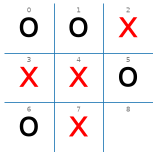

Available actions are: [8]


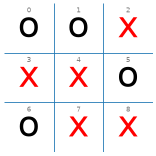

{'x': 0, 'o': 0, 'd': 1}

In [7]:
play(interactive_player, and_or_player, N = 1,  show_final_board=True)

**Nhận xét (người chơi X vs. AND-OR):** Ván kết thúc hòa. Bàn cờ cuối: X ở các ô 2, 3, 4, 7, 8 và O (AND-OR) ở các ô 0, 1, 5, 6. Mỗi khi X tạo đe dọa hai quân thẳng hàng, AND-OR đều chặn đúng ô còn lại nên X không thắng được. AND-OR chơi phòng thủ: nó chọn nước đi bảo đảm không thua, nên khi người chơi không mắc sai lầm thì kết quả là hòa.

### Start an interactive game as o

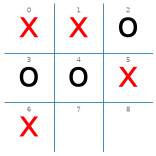

Available actions are: [7, 8]


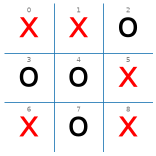

{'x': 0, 'o': 0, 'd': 1}

In [8]:
play(and_or_player, interactive_player, N = 1, show_final_board = True)

**Nhận xét (người chơi O vs. AND-OR):** Ván kết thúc hòa. Bàn cờ cuối: X (AND-OR) ở các ô 0, 1, 5, 6, 8 và O ở các ô 2, 3, 4, 7. AND-OR đi trước và mở đầu ở góc 0 (nước đầu tiên theo thứ tự duyệt có kế hoạch bảo đảm ít nhất hòa).

**Nhận xét chiến lược của tác tử:** and_or_player không tìm nước thắng nhanh nhất mà chọn nước đầu tiên theo thứ tự ô 0 đến 8 có kế hoạch bảo đảm thắng hoặc hòa, nên cách chơi hơi máy móc nhưng không thua khi còn kế hoạch. Nó luôn chặn các đường thẳng sắp hoàn thành của đối thủ và tận dụng sai lầm của đối thủ để thắng. Hạn chế là khi không còn kế hoạch bảo đảm (đối thủ đã tạo thế thắng), tác tử đi ngẫu nhiên và không biết nước nào ít tệ nhất. Ngoài ra nó chậm vì tính lại kế hoạch ở mỗi nước đi, nhưng với 9 ô thì vẫn đủ nhanh để chơi tương tác.